In [1]:
!pip install matplotlib
!pip install seaborn
%pip install scikit-learn
%pip install pandas

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

df_black_friday_sales = pd.read_csv('./BlackFriday.csv')
print(df_black_friday_sales.head())

   User_ID Product_ID Gender   Age  Occupation City_Category  \
0  1000001  P00069042      F  0-17          10             A   
1  1000001  P00248942      F  0-17          10             A   
2  1000001  P00087842      F  0-17          10             A   
3  1000001  P00085442      F  0-17          10             A   
4  1000002  P00285442      M   55+          16             C   

  Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                          2               0                   3   
1                          2               0                   1   
2                          2               0                  12   
3                          2               0                  12   
4                         4+               0                   8   

   Product_Category_2  Product_Category_3  Purchase  
0                 NaN                 NaN      8370  
1                 6.0                14.0     15200  
2                 NaN                 NaN   

In [4]:
# Handling missing value
print( df_black_friday_sales.isna().any() )

User_ID                       False
Product_ID                    False
Gender                        False
Age                           False
Occupation                    False
City_Category                 False
Stay_In_Current_City_Years    False
Marital_Status                False
Product_Category_1            False
Product_Category_2             True
Product_Category_3             True
Purchase                      False
dtype: bool


In [5]:
# total number of null values
df_black_friday_sales.isnull().sum()

User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            166986
Product_Category_3            373299
Purchase                           0
dtype: int64

In [7]:
# Fill missing values (NaN) in Product_Category_2 with-2.0 
# Then convert the column to float32 data type
df_black_friday_sales['Product_Category_2'] =(
    df_black_friday_sales['Product_Category_2'] 
 .fillna(-2.0)
 .astype("float32") 
)
# Fill missing values (NaN) in Product_Category_3 with-2.0
# Then convert the column to float32 data type
df_black_friday_sales['Product_Category_3'] = (
    df_black_friday_sales['Product_Category_3'] 
    .fillna(-2.0)
    .astype("float32") 
) 

#Find themean(average)ofthenumeric columns
#and use those averagestofillremaining missing values
df_black_friday_sales.fillna( 
    df_black_friday_sales.mean(numeric_only=True),
    inplace=True

) #Display the first 5 rowsofthedataset 
print(df_black_friday_sales.head())

   User_ID Product_ID Gender   Age  Occupation City_Category  \
0  1000001  P00069042      F  0-17          10             A   
1  1000001  P00248942      F  0-17          10             A   
2  1000001  P00087842      F  0-17          10             A   
3  1000001  P00085442      F  0-17          10             A   
4  1000002  P00285442      M   55+          16             C   

  Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                          2               0                   3   
1                          2               0                   1   
2                          2               0                  12   
3                          2               0                  12   
4                         4+               0                   8   

   Product_Category_2  Product_Category_3  Purchase  
0                -2.0                -2.0      8370  
1                 6.0                14.0     15200  
2                -2.0                -2.0   

In [9]:
##Dealingwith duplicates
#finding duplicates
df_black_friday_sales[df_black_friday_sales.duplicated()].count().sum()

0

In [10]:
#dropping the duplicates 
df =df_black_friday_sales 
df_cleaned= df.drop_duplicates()
#reset the index after droppingduplicates 
df_cleaned = df_cleaned.reset_index(drop=True)

In [11]:
# Import MinMaxScaler from scikit-learn 
# MinMaxScaler is used to scale numerical values to a fixed range, usually 0 to␣ ↪1
from sklearn.preprocessing import MinMaxScaler

# Create an instance (object) of MinMaxScaler
scaler = MinMaxScaler()
# Apply Min-Max scaling to the 'Purchase' column 
# [['Purchase']] uses double brackets because fit_transform() 
# expects a 2-dimensional DataFrame
# 
# The original Purchase values are converted to values between 0 and 1
df_black_friday_sales['Purchase'] = scaler.fit_transform(
    df_black_friday_sales[['Purchase']] )

# Display the first 5 rows of the dataset
# This allows us to check the scaled Purchase values
print(df_black_friday_sales.head())

   User_ID Product_ID Gender   Age  Occupation City_Category  \
0  1000001  P00069042      F  0-17          10             A   
1  1000001  P00248942      F  0-17          10             A   
2  1000001  P00087842      F  0-17          10             A   
3  1000001  P00085442      F  0-17          10             A   
4  1000002  P00285442      M   55+          16             C   

  Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                          2               0                   3   
1                          2               0                   1   
2                          2               0                  12   
3                          2               0                  12   
4                         4+               0                   8   

   Product_Category_2  Product_Category_3  Purchase  
0                -2.0                -2.0  0.344255  
1                 6.0                14.0  0.631519  
2                -2.0                -2.0  0

In [4]:
# Create a dictionary to map the original age ranges
# to meaningful age-group names
age_mapping = {
'0-17': 'toddler',
'18-25': 'young_adult',
'26-35': 'adult',
'36-45': 'middle_age',
'46-50': 'mid_age',
'51-55': 'older_adult',
'55+': 'elderly'
}

# Map the values of the 'Age' column using the age_mapping dictionary
# For example:
# '18-25' → 'young_adult'
# '26-35' → 'adult'
# The new values are stored in a new column called 'Age_new'
df_black_friday_sales['Age_new'] = df_black_friday_sales['Age'].map(age_mapping)

# Convert the categorical 'Age_new' column into dummy/indicator variables
# drop_first=True removes the first category to avoid redundant columns
df_black_friday_sales = pd.get_dummies(
df_black_friday_sales,
columns=['Age_new'],
drop_first=True
)

# List of categorical columns that we want to convert into numerical values
cols = ['City_Category', 'Stay_In_Current_City_Years']

# Import LabelEncoder from scikit-learn
# LabelEncoder converts categorical text values into numbers
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
le = LabelEncoder()

# Loop through each column in the 'cols' list
for col in cols:
# Convert the text/category values into numerical values
# Example:
# A → 0
# B → 1
# C → 2
    df_black_friday_sales[col] = le.fit_transform(
        df_black_friday_sales[col]
)

# Display the first 5 rows of the final DataFrame
df_black_friday_sales.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase,Age_new_elderly,Age_new_mid_age,Age_new_middle_age,Age_new_older_adult,Age_new_toddler,Age_new_young_adult
0,1000001,P00069042,F,0-17,10,0,2,0,3,NaN,NaN,8370,False,False,False,False,True,False
1,1000001,P00248942,F,0-17,10,0,2,0,1,6.0,14.0,15200,False,False,False,False,True,False
2,1000001,P00087842,F,0-17,10,0,2,0,12,NaN,NaN,1422,False,False,False,False,True,False
3,1000001,P00085442,F,0-17,10,0,2,0,12,14.0,NaN,1057,False,False,False,False,True,False
4,1000002,P00285442,M,55+,16,2,4,0,8,NaN,NaN,7969,True,False,False,False,False,False


In [5]:
# Print the number of rows and columns in the dataset
# .shape returns (number of rows, number of columns)
print("Dimensions of the dataset: ", df_black_friday_sales.shape, "\n\n")

Dimensions of the dataset:  (537577, 18) 




In [6]:
# Display a summary of the dataset
# .info() shows column names, data types, and non-null values
df_black_friday_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 537577 entries, 0 to 537576
Data columns (total 18 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     537577 non-null  int64  
 1   Product_ID                  537577 non-null  object 
 2   Gender                      537577 non-null  object 
 3   Age                         537577 non-null  object 
 4   Occupation                  537577 non-null  int64  
 5   City_Category               537577 non-null  int32  
 6   Stay_In_Current_City_Years  537577 non-null  int32  
 7   Marital_Status              537577 non-null  int64  
 8   Product_Category_1          537577 non-null  int64  
 9   Product_Category_2          370591 non-null  float64
 10  Product_Category_3          164278 non-null  float64
 11  Purchase                    537577 non-null  int64  
 12  Age_new_elderly             537577 non-null  bool   
 13  Age_new_mid_ag

In [7]:
# Display the dimensions of the dataset
# .shape returns the number of rows and columns
print("Dimensions of the dataset:", df_black_friday_sales.shape, "\n\n")
# Display the summary/information of the dataset
# .info() shows column names, data types, and non-null values
df_black_friday_sales.info()

Dimensions of the dataset: (537577, 18) 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 537577 entries, 0 to 537576
Data columns (total 18 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     537577 non-null  int64  
 1   Product_ID                  537577 non-null  object 
 2   Gender                      537577 non-null  object 
 3   Age                         537577 non-null  object 
 4   Occupation                  537577 non-null  int64  
 5   City_Category               537577 non-null  int32  
 6   Stay_In_Current_City_Years  537577 non-null  int32  
 7   Marital_Status              537577 non-null  int64  
 8   Product_Category_1          537577 non-null  int64  
 9   Product_Category_2          370591 non-null  float64
 10  Product_Category_3          164278 non-null  float64
 11  Purchase                    537577 non-null  int64  
 12  Age_new_elderly             5

In [8]:
# Find all unique values in the 'Gender' column
unique_values_gender = df_black_friday_sales['Gender'].unique()
# Find all unique values in the 'Age' column
unique_values_age = df_black_friday_sales['Age'].unique()
# Find all unique values in the 'City_Category' column
unique_values_city_category = df_black_friday_sales['City_Category'].unique()

# Print the unique values in the Gender column
print("\nUnique values for 'Gender':", unique_values_gender)
# Print the unique values in the Age column
print("\nUnique values for 'Age':", unique_values_age)
# Print the unique values in the City_Category column
print("\nUnique values for 'City_Category':", unique_values_city_category)


Unique values for 'Gender': ['F' 'M']

Unique values for 'Age': ['0-17' '55+' '26-35' '46-50' '51-55' '36-45' '18-25']

Unique values for 'City_Category': [0 2 1]


In [16]:
# Convert Gender from categorical values to numerical values
# M = 0 and F = 1
df_black_friday_sales['Gender'] = df_black_friday_sales['Gender'].replace({
'M': 0,
'F': 1
})
# Check the first 5 values
print(df_black_friday_sales['Gender'].head())

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: Gender, dtype: float64


In [17]:
print( df_black_friday_sales.describe() )

            User_ID  Gender    Occupation  City_Category  \
count  5.375770e+05     0.0  537577.00000  537577.000000   
mean   1.002992e+06     NaN       8.08271       1.040567   
std    1.714393e+03     NaN       6.52412       0.759627   
min    1.000001e+06     NaN       0.00000       0.000000   
25%    1.001495e+06     NaN       2.00000       0.000000   
50%    1.003031e+06     NaN       7.00000       1.000000   
75%    1.004417e+06     NaN      14.00000       2.000000   
max    1.006040e+06     NaN      20.00000       2.000000   

       Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
count               537577.000000   537577.000000       537577.000000   
mean                     1.859458        0.408797            5.295546   
std                      1.289828        0.491612            3.750701   
min                      0.000000        0.000000            1.000000   
25%                      1.000000        0.000000            1.000000   
50%                  

In [11]:
# Printing the data types of all columns
print("Data Types:\n")
# .dtypes shows the data type of each column
print(df_black_friday_sales.dtypes)

# Get all unique values from the 'City_Category' column
unique_values = df_black_friday_sales['City_Category'].unique()
# Print the heading
print("\nUnique Values in 'City_Category':")
# Print the unique values
print(unique_values)

Data Types:

User_ID                         int64
Product_ID                     object
Gender                          int64
Age                            object
Occupation                      int64
City_Category                   int32
Stay_In_Current_City_Years      int32
Marital_Status                  int64
Product_Category_1              int64
Product_Category_2            float64
Product_Category_3            float64
Purchase                        int64
Age_new_elderly                  bool
Age_new_mid_age                  bool
Age_new_middle_age               bool
Age_new_older_adult              bool
Age_new_toddler                  bool
Age_new_young_adult              bool
dtype: object

Unique Values in 'City_Category':
[0 2 1]


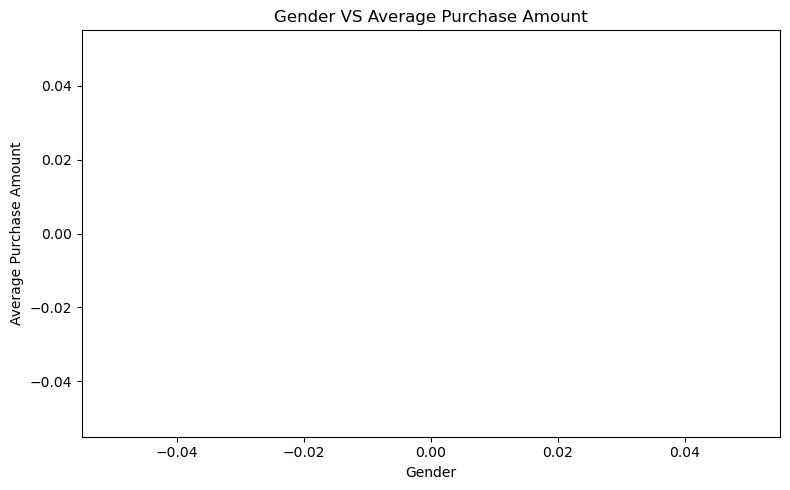

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Calculate average purchase amount by Gender
avg_purchase = df_black_friday_sales.groupby('Gender')['Purchase'].mean()

# Create bar plot
plt.figure(figsize=(8, 5))
plt.bar(avg_purchase.index, avg_purchase.values)

# Add title and labels
plt.title("Gender VS Average Purchase Amount")
plt.xlabel("Gender")
plt.ylabel("Average Purchase Amount")

# Display bars and graph
plt.tight_layout()
plt.show()